In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm,poisson,bernoulli

mean: 0.003743000000000002 0.0035
var: 0.0034932989510000007 0.0035


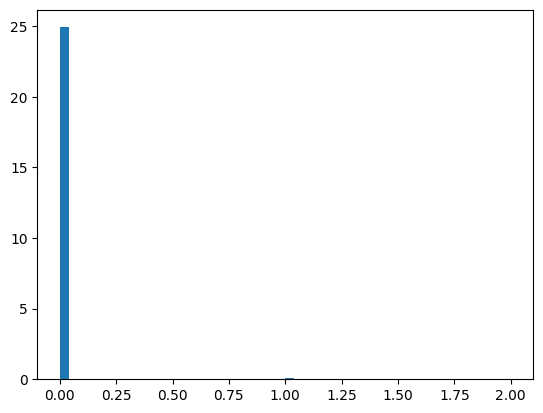

In [2]:
def microscopic(S,tmax,dt,x0,W,h):
    x = np.zeros((tmax,S))
    x[0] = x0#np.random.rand(S) #+ init
    for t in range(0,tmax-1):
        dx = dt*(W @ x[t] - x[t] * (W.T @ np.ones_like(x[t]))- h*x[t])
        x[t+1] = x[t] + dx
        if np.any(x[t+1]<0):
            print('negative value at time',t)
            x[t+1][x[t+1]<0]=0
    return x



def transition_rates(S, c, beta,mu):
    W = beta * poisson.rvs(c/S, size=(S, S)) +mu/S
    return W

def transition_rates_gamma(S, c, beta, mu):
    shape = c/S
    scale = beta
    W = np.random.gamma(shape, scale, size=(S, S)) + mu/S
    return W

def transition_rates_normal(S, c, beta, mu):
    W = bernoulli.rvs(c/S, size=(S, S))*np.random.normal(loc=0, scale=beta, size=(S, S)) + mu/S
    return W

def contrained_transition_rates(S, c1, c2, beta1,beta2, mu):
    W = np.zeros((S, S))
    e = np.zeros((S))
    B = np.zeros((S,S))
    e = beta1* poisson.rvs(c1, size=(S))
    b = beta2* poisson.rvs(c2/S, size=(S, S))
    # W_ij = E_j * B_ij
    W = np.outer(e, np.ones(S))*b
    return W

S = 2000
c=7
beta=1
mu =0.5
mass=1

# constrained params
W = transition_rates(S, c,beta, mu)
print('mean:', np.mean(W),c*beta/S)
print('var:',np.var(W),c*(beta**2)/S)
plt.hist(W.flatten(),density=True, bins=50);
plt.show()

#plt.bar(beta*a_space, beta*poisson.pmf(a_space,c/S),width=beta/2)

number of rows with 0 entries above mu/S: 0
number of rows with entries below 0: 0


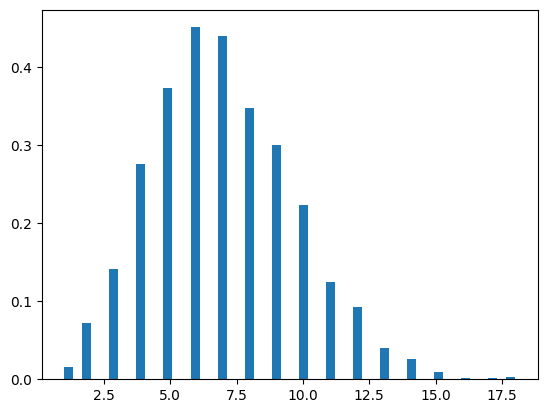

In [152]:
# histogram of how many entries above mu/S in W rows
plt.hist(np.sum(W>mu/S, axis=1), density=True, bins=50);
#number of rows with 0 entries above mu/S
print('number of rows with 0 entries above mu/S:', np.sum(np.sum(W>mu/S, axis=1)==0))   
print('number of rows with entries below 0:', np.sum(np.sum(W<0, axis=1)==1))
plt.show()

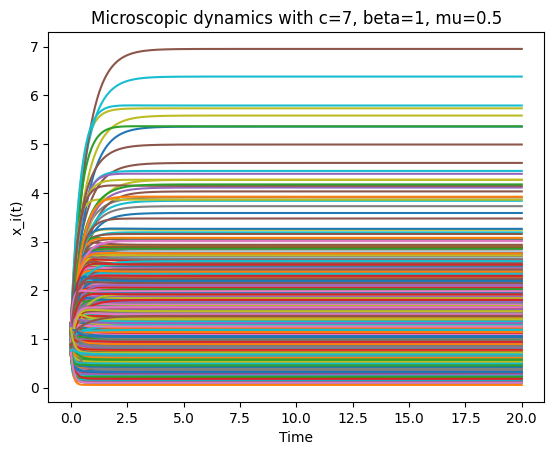

In [153]:
t_steps = 2000
dt = 0.01
tmax= dt*t_steps
ts = np.linspace(0,tmax,t_steps)

total_mass = S*mass
h= 0#beta
647


N = 1 # number of realisatons for the microscopic dynamics    

means_micro = np.zeros(t_steps)
vars_micro = np.zeros(t_steps)

for _ in range(N):
    x0= np.ones(S)+beta*np.random.rand(S)
    x0= x0 /(np.sum(x0))*total_mass
    microscopic_x = microscopic(S,t_steps,dt,x0,W,h)
    means_micro += np.mean(microscopic_x,axis=1)/N
    vars_micro += np.var(microscopic_x,axis=1)/N
    
    for i in range(S):
        plt.plot(ts, microscopic_x.T[i])

    

plt.xlabel('Time')
plt.ylabel('x_i(t)')
plt.title(f'Microscopic dynamics with c={c}, beta={beta}, mu={mu}')
plt.show()

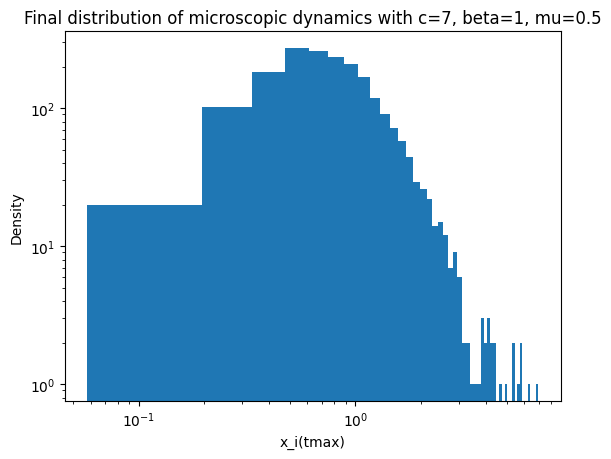

mean: 0.9999999999997917
var: 0.4620710279757779
var/mean^2: 0.4620710279759704
var/mean^2 (theoretical for mu=0): 0.3333333333333333
mean spacing: 0.003450225112556278


In [154]:
final = microscopic_x[-1]
plt.hist(final, bins=50);
plt.xscale('log')
plt.yscale('log')
plt.xlabel('x_i(tmax)')
plt.ylabel('Density')



plt.title(f'Final distribution of microscopic dynamics with c={c}, beta={beta}, mu={mu}')
plt.show()
print('mean:', np.mean(final))
print('var:', np.var(final))
print('var/mean^2:', np.var(final)/np.mean(final)**2)
print('var/mean^2 (theoretical for mu=0):', 2/(c-1))
#print('total mass:', np.sum(final))

# the distribution is close to a discrete lattice, the length of the lattice is empirically estimated as the mean spacing between values in the distribution, rounded to 1 decimal place
mean_spacing = np.mean(np.diff(np.round(np.sort(final),4)))
print('mean spacing:', mean_spacing)


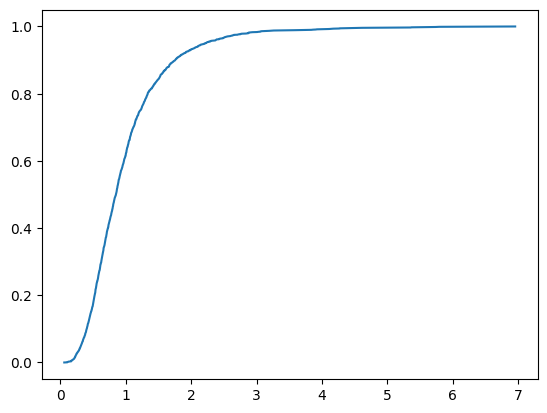

In [155]:
def cumuldensity(srv):
    data_sorted = np.sort(srv)

    # calculate the proportional values of samples
    p = 1. * np.arange(len(srv)) / (len(srv) - 1)

    return p,data_sorted

p,data_sorted = cumuldensity(final)
plt.plot(data_sorted,p)

0.020025875716459748
3.2691191718811705 0.30589279479357845
Gamma fit parameters: shape= 1.0025048912296488 loc= 0.05778507372842412 scale= 0.9103813815395954
0.9999999999997917 0.4620710279757779


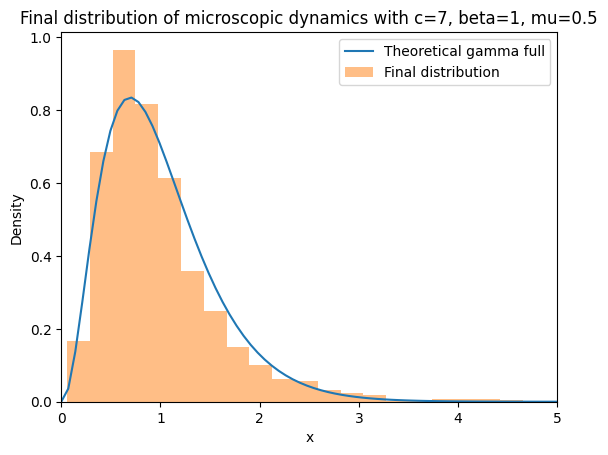

In [156]:
# fit final distribution to a2/(c-1) gamma distribution
from scipy.stats import gamma
shape, loc, scale = gamma.fit(final)
x = np.linspace(0, 7, 100)
pdf_fit = gamma.pdf(x, shape, loc, scale)
#plt.plot(x, pdf_fit, label='Gamma fit')
shape_pred = (c-1+mu/beta)/2 
scale_pred = mass*((c-1+mu/beta)/2 )**(-1)
shape_pred_0 = (c-1)/2 
scale_pred_0 = mass*((c-1)/2 )**(-1)


u2b= poisson.expect(lambda x: (beta*x+beta+mu)**(-2), args=(c,))
print(u2b)
shape_pred_full=((1+(c-1)*c*beta**2*u2b)/(c*(1-c*beta**2*u2b)))**(-1)
scale_pred_full=mass/shape_pred_full
print(shape_pred_full,scale_pred_full)

pdf_predict = gamma.pdf(x, shape_pred, loc=0, scale=scale_pred)
pdf_predict_0 = gamma.pdf(x, shape_pred_0, loc=0, scale=scale_pred_0)
pdf_predict_full = gamma.pdf(x, shape_pred_full, loc=0, scale=scale_pred_full)
gaussian_predict =norm.pdf(x,loc=mass,scale=scale_pred_full)

#plt.plot(x, pdf_predict, label='Theoretical gamma 1˚ in mu')
#plt.plot(x, pdf_predict_0, label='Theoretical gamma mu=0')
plt.plot(x,pdf_predict_full, label='Theoretical gamma full')
#plt.plot(x,gaussian_predict,label='Theoretical gaussian')

plt.hist(final, bins=30, density=True, alpha=0.5, label='Final distribution')
print('Gamma fit parameters: shape=', shape, 'loc=', loc, 'scale=', scale)
print(np.mean(final), np.var(final))
plt.xlim(0, 5)
plt.xlabel('x')
plt.ylabel('Density')
plt.title(f'Final distribution of microscopic dynamics with c={c}, beta={beta}, mu={mu}')
plt.legend()
plt.show()

excluded values: [5.73561365 5.79294447 6.3873525  6.95478475]
mean without 4 largest values: 0.9895437397948624
var without 4 largest values: 0.4078368962049221
var/mean^2 without 4 largest values: 0.4165014538487702


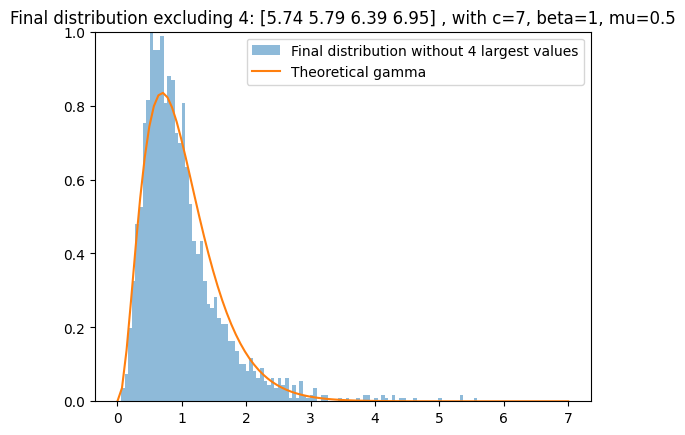

In [157]:
#final without 3 largest values
excluded_number=4
final_no3 = np.sort(final)[:-excluded_number]
excluded_values = np.sort(final)[-excluded_number:]
print(f'excluded values: {excluded_values}')
plt.hist(final_no3, bins=100, density=True, alpha=0.5, label=f'Final distribution without {excluded_number} largest values')
print(f'mean without {excluded_number} largest values:', np.mean(final_no3))
print(f'var without {excluded_number} largest values:', np.var(final_no3))
print(f'var/mean^2 without {excluded_number} largest values:', np.var(final_no3)/np.mean(final_no3)**2)
plt.plot(x, pdf_predict_full, label='Theoretical gamma')
plt.ylim(0,1)
plt.title(f'Final distribution excluding {excluded_number}: {np.round(excluded_values, 2)} , with c={c}, beta={beta}, mu={mu}')
plt.legend()
plt.show()

In [81]:
# entropy production of the final distribution
def stat_entropy_production(final,W):
    # compute the stationary distribution
    p = final#/np.sum(final)
    # compute the entropy production
    ep = 0
    for i in range(len(final)):
        for j in range(len(final)):
            if W[i,j]>0 and p[i]>0 and p[j]>0:
                ep += 0.5*(W[i,j]*p[j]-W[j,i]*p[i])*np.log(W[i,j] * p[j]/(W[j,i]*p[i]))
    return ep/(S*np.log(S))

def U1(c,beta,q,mu):
    def reciprocal(k):
        return (beta*k+q+mu)**(-1)
    return poisson.expect(reciprocal,args=(c,))

def dynamic_entropy_production(x,W):
    ep= np.zeros(x.shape[0]//100)
    for t in range(x.shape[0]//100):
        T= t*100
        ep[t] =stat_entropy_production(x[T],W)
    return ep

predicted_ep = c*beta*U1(c,beta,beta,mu)/U1(c,beta,0,mu)
print('entropy production of the final distribution:', stat_entropy_production(final,W))
print('predicted entropy production of the final distribution:', predicted_ep)
entropy_prod= dynamic_entropy_production(microscopic_x,W)




entropy production of the final distribution: 11.473351577959816
predicted entropy production of the final distribution: 13.048201577337897


In [69]:
np.sum(final)

np.float64(2000.0000000000355)

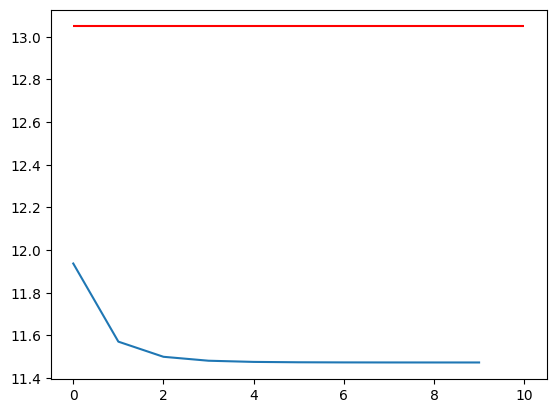

In [82]:
plt.plot(entropy_prod)
plt.hlines(predicted_ep,0,10,colors='r')

In [17]:
2 *S *c*beta*np.log(beta/mu)- np.log(S)*(c*mu+c**2*beta) +c*mu*np.log(mu/beta) +c**2*beta*np.log(mu/beta)+ np.log(S)/S *(c**2 *mu + c*beta)

np.float64(76074.43720459791)

In [7]:
# save gamma fit parameters given c
import pickle
with open('gamma_fit_params.pkl', 'wb') as f:
    pickle.dump({'c': c, 'shape': shape, 'loc': loc, 'scale': scale}, f) 


In [74]:
# plot variance of stationary distribution as a function of c
cs = np.arange(3, 99, 3)
variances = []
skewnesses = []
kurtoses = []
for c in cs:
    W = transition_rates(S, c, beta)
    x0= np.ones(S)
    x0= x0 /(np.sum(x0))*total_mass
    microscopic_x = microscopic(S,t_steps,dt,x0,W,h)
    final = microscopic_x[-1]
    variances.append(np.var(final))
    skewnesses.append(np.mean((final - np.mean(final))**3) )
    kurtoses.append(np.mean((final - np.mean(final))**4) - 3 * (np.var(final)**2)) 



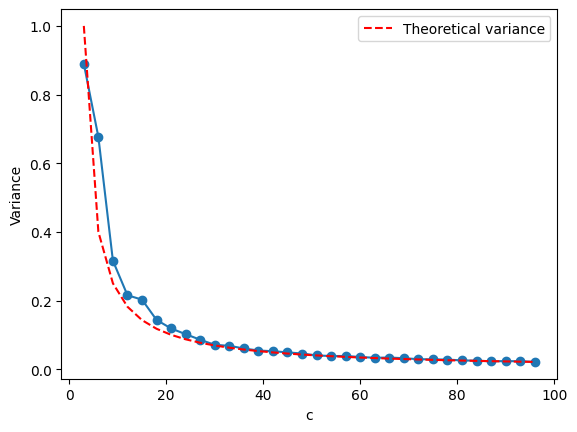

In [75]:
plt.plot(cs, variances, 'o-')
plt.plot(cs, 2/(cs-1), 'r--', label='Theoretical variance')
plt.xlabel('c')
plt.ylabel('Variance')
plt.legend()
plt.show()

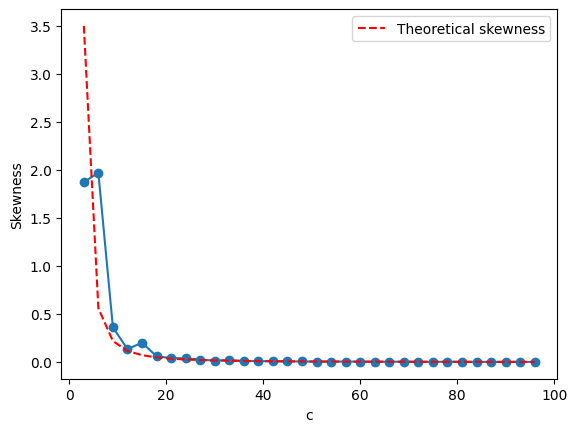

In [82]:
plt.plot(cs, skewnesses, 'o-')

plt.plot(cs, 14/(cs-1)**2, 'r--', label='Theoretical skewness')
plt.xlabel('c')
plt.ylabel('Skewness')
plt.legend()
plt.show()

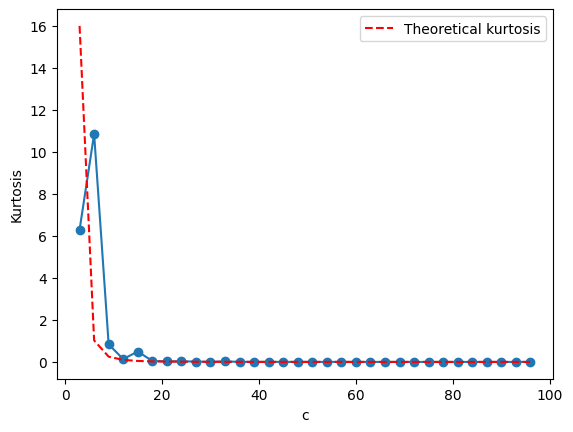

In [78]:
plt.plot(cs, kurtoses, 'o-')
plt.xlabel('c')
plt.plot(cs, 128/(cs-1)**3, 'r--', label='Theoretical kurtosis')
plt.ylabel('Kurtosis')
plt.legend()
plt.show()